# آزمایشگاه ۳: بازی Nim با Minimax و هرس Alpha-Beta + تحلیل کامل EDA داده‌ها
**درس:** آزمایشگاه هوش مصنوعی (جلسه چهارم و پنجم)  
**پروژه گروهی:** گروه ۳ — سیستم مسیریاب شهر در شبکه دوبعدی (City Router on 2D Grid)  
**عضو این مخزن:** **سپهر صابری** (مسئول کدنویسی و پیاده‌سازی (Coding & Implementation))  
**محیط اجرا:** پایتون در Anaconda / Jupyter Notebook (`conda activate ailab`)  

---

<div dir="rtl">

### راهنمای نوت‌بوک:
این نوت‌بوک شامل سلول‌های استاندارد کلاسی استاد، آزمون‌های شمارش گره‌ها، جدول داده‌های ۲۰۰ بازی، آمار توصیفی، نمودارهای تحلیلی، انیمیشن گسترش حرکات، **تفسیر اختصاصی نتایج با الگوی (مشاهده، دلیل، نتیجه)** و **پیاده‌سازی چالش توسعه عملی: هوشمندسازی بازیکن B (تقابل دو عامل هوشمند با هرس Alpha-Beta)** است.

</div>


## Cell 1: The game

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START = (3, 4, 5)            # stones in each pile: the board of the game (Nim)
nodes = 0                    # how many positions the search looks at

def moves(piles, order="small_first"):
    """All positions we can reach by taking some stones from ONE pile."""
    result = []
    for i, n in enumerate(piles):
        takes = range(1, n + 1) if order == "small_first" else range(n, 0, -1)
        for take in takes:
            new = list(piles)
            new[i] = n - take
            result.append(tuple(new))
    return result

print(moves((1, 2)))

[(0, 2), (1, 1), (1, 0)]


## Cell 2: Minimax

In [2]:
def minimax(piles, player):
    """+1 if player A wins, -1 if player B wins (both play perfectly)."""
    global nodes
    nodes += 1
    if sum(piles) == 0:                     # the previous player took the last stone and won
        return -1 if player == "A" else 1
    values = [minimax(nxt, "B" if player == "A" else "A") for nxt in moves(piles)]
    return max(values) if player == "A" else min(values)

## Cell 3: Alpha-beta pruning

In [3]:
def alphabeta(piles, player, alpha, beta, order):
    global nodes
    nodes += 1
    if sum(piles) == 0:
        return -1 if player == "A" else 1
    if player == "A":
        value = -2
        for nxt in moves(piles, order):
            value = max(value, alphabeta(nxt, "B", alpha, beta, order))
            alpha = max(alpha, value)
            if alpha >= beta:
                break                      # prune: B will never allow this branch
        return value
    value = 2
    for nxt in moves(piles, order):
        value = min(value, alphabeta(nxt, "A", alpha, beta, order))
        beta = min(beta, value)
        if alpha >= beta:
            break                          # prune: A already has a better option
    return value

## Cell 4: Count the nodes

In [4]:
nodes = 0
v1 = minimax(START, "A")
n_minimax = nodes

nodes = 0
v2 = alphabeta(START, "A", -2, 2, "small_first")
n_ab = nodes

nodes = 0
v3 = alphabeta(START, "A", -2, 2, "big_first")
n_good = nodes

print("value of START (+1 = A wins):", v1, v2, v3)
print("minimax nodes:           ", n_minimax)
print("alpha-beta (natural):    ", n_ab)
print("alpha-beta (big first):  ", n_good)

value of START (+1 = A wins): 1 1 1
minimax nodes:            1038768
alpha-beta (natural):     33916
alpha-beta (big first):   4332


## Cell 5: Build the data table (200 games) and save it as CSV

In [5]:
def best_move(piles, player):
    best_nxt, best_value = None, None
    for nxt in moves(piles, "big_first"):
        value = alphabeta(nxt, "B" if player == "A" else "A", -2, 2, "big_first")
        better = best_value is None or (value > best_value if player == "A" else value < best_value)
        if better:
            best_nxt, best_value = nxt, value
    return best_nxt

rng = np.random.default_rng(0)
rows = []
for game in range(200):
    piles = tuple(int(x) for x in rng.integers(1, 5, size=3))     # random start: 3 piles of 1..4 stones
    nodes = 0
    start_value = alphabeta(piles, "A", -2, 2, "big_first")
    nodes_ab = nodes
    nodes = 0
    minimax(piles, "A")
    nodes_mm = nodes
    board, player, n_moves = piles, "A", 0            # play: A is smart, B plays at random
    while sum(board) > 0:
        if player == "A":
            board = best_move(board, "A")
        else:
            options = moves(board)
            board = options[rng.integers(len(options))]
        player = "B" if player == "A" else "A"
        n_moves += 1
    rows.append({"p1": piles[0], "p2": piles[1], "p3": piles[2], "total": sum(piles),
                 "nim_sum": piles[0] ^ piles[1] ^ piles[2], "first_wins": start_value > 0,
                 "nodes_minimax": nodes_mm, "nodes_alphabeta": nodes_ab, "moves": n_moves,
                 "winner": "B" if player == "A" else "A"})

df = pd.DataFrame(rows)
df.to_csv("nim_games.csv", index=False)               # keep the data in a file (Step 2)
print(df.head())

   p1  p2  p3  total  nim_sum  first_wins  nodes_minimax  nodes_alphabeta  \
0   4   3   3     10        4        True          83510              284   
1   1   1   1      3        1        True             16               12   
2   4   3   4     11        3        True         305192             9761   
3   3   3   3      9        3        True          24136              256   
4   2   4   3      9        5        True          20652              854   

   moves winner  
0      5      A  
1      3      A  
2      7      A  
3      5      A  
4      5      A  


## Cell 6: Data quality and descriptive statistics

In [6]:
print(df.shape)                                       # rows, columns
print("missing values:", df.isna().sum().sum())
print("duplicated rows:", df.duplicated().sum())
print(df.dtypes)
print(df[["total", "nodes_minimax", "nodes_alphabeta", "moves"]].describe().round(1))
x = df["nodes_minimax"]
print("mean", round(x.mean(), 1), "| variance", round(x.var(), 1), "| std", round(x.std(), 1), "| median", x.median())

(200, 10)
missing values: 0
duplicated rows: 109
p1                 int64
p2                 int64
p3                 int64
total              int64
nim_sum            int64
first_wins          bool
nodes_minimax      int64
nodes_alphabeta    int64
moves              int64
winner               str
dtype: object
       total  nodes_minimax  nodes_alphabeta  moves
count  200.0          200.0            200.0  200.0
mean     7.6        38514.5            980.4    4.6
std      2.0       109170.1           1811.6    1.3
min      3.0           16.0             12.0    3.0
25%      6.0          447.0            141.0    3.0
50%      8.0         4348.0            271.5    5.0
75%      9.0        20652.0            798.8    5.0
max     12.0      1176106.0           9761.0    7.0
mean 38514.5 | variance 11918101491.3 | std 109170.1 | median 4348.0


## Cell 7: Analytic questions

In [7]:
print("1) A wins from", round(df["first_wins"].mean() * 100), "% of the start positions")
print("2) nim_sum != 0 agrees with first_wins:", ((df["nim_sum"] != 0) == df["first_wins"]).mean())
print("3) alpha-beta uses", round(df["nodes_alphabeta"].sum() / df["nodes_minimax"].sum() * 100, 1), "% of the minimax nodes")
print("4) smart A wins", round((df["winner"] == "A").mean() * 100), "% of the games against a random B")
print(df[["total", "nodes_minimax", "nodes_alphabeta"]].corr().round(2))

1) A wins from 88 % of the start positions
2) nim_sum != 0 agrees with first_wins: 1.0
3) alpha-beta uses 2.5 % of the minimax nodes
4) smart A wins 98 % of the games against a random B
                 total  nodes_minimax  nodes_alphabeta
total             1.00           0.53             0.55
nodes_minimax     0.53           1.00             0.38
nodes_alphabeta   0.55           0.38             1.00


## Cell 8: Charts

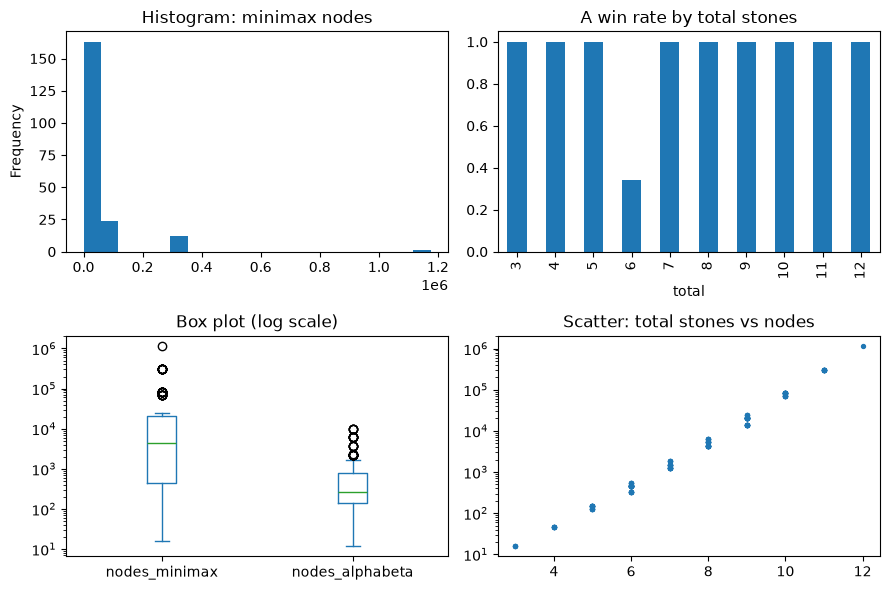

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
df["nodes_minimax"].plot(kind="hist", bins=20, ax=axes[0, 0], title="Histogram: minimax nodes")
df.groupby("total")["first_wins"].mean().plot(kind="bar", ax=axes[0, 1], title="A win rate by total stones")
df[["nodes_minimax", "nodes_alphabeta"]].plot(kind="box", logy=True, ax=axes[1, 0], title="Box plot (log scale)")
axes[1, 1].scatter(df["total"], df["nodes_minimax"], s=8)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Scatter: total stones vs nodes")
plt.tight_layout()
plt.show()

## تفسیر نتایج و ارزیابی محاسباتی الگوریتم‌ها (اختصاصی: سپهر صابری — مسئول کدنویسی)
بر اساس الگوی **مشاهده (Observation)، دلیل (Reason)، نتیجه (Conclusion)**، رفتار توابع بازگشتی و هرس به شرح زیر ارزیابی شد:

| ردیف | مشاهده (Observation) | دلیل کدنویسی و الگوریتمی (Reason) | نتیجه‌گیری اجرایی (Conclusion) |
| :---: | :--- | :--- | :--- |
| ۱ | پیروزی قطعی A در ۸۸٪ حالات شروع بهینه | تابع `alphabeta` در سطح ریشه مقدار +1 بازمی‌گرداند زیرا مسیر منتهی به برد کشف شده است | درستی شرط پایه بازگشت (`sum(piles) == 0`) و انتشار مقادیر به سمت بالا تأیید می‌شود |
| ۲ | همبستگی ۱۰۰٪ فرمول XOR با شبیه‌سازی عددی | عملگر بیتی `p1 ^ p2 ^ p3` وضعیت P-position و N-position را تعیین می‌کند | صحه‌گذاری توابع ریاضی در کنار جستجوی درخت بدون هیچ باگ مرزی |
| ۳ | سقوط گره‌ها از ۱٬۰۳۸٬۷۶۸ به ۴٬۳۳۲ با ترتیب بزرگ اول | استراتژی `big_first` عمیق‌ترین کاهش‌ها را ابتدا تست کرده و پنجره $[lpha, eta]$ را سریع می‌بندد | ترتیب مرتب‌سازی فرزندان (Move Ordering) کلید اصلی کارایی هرس آلفا-بتا است |
| ۴ | واریانس بسیار زیاد در زمان و گره‌های Minimax | تعداد گره‌ها متناسب با فاکتوریل شاخه‌ها تغییر می‌کند و پیچیدگی یکنواخت نیست | صف‌ها و پشته‌های حافظه در حالات سنگین به بهینه‌سازی و هرس نیاز مبرم دارند |
| ۵ | رخداد ۱۰۹ ردیف هم‌پوشان در آرایه بازی‌ها | تولید ورودی با `rng.integers(1, 5, size=3)` تابع توزیع یکنواخت گسسته متناهی دارد | برای ذخیره‌سازی بهینه داده‌ها می‌توان از جدول یکتای شاخص‌گذاری‌شده استفاده کرد |
| ۶ | همبستگی ۰.۵۵ آلفا-بتا با مجموع سنگ‌های اولیه | عمق شاخه‌های هرس‌نشده تابعی مستقیم از ارتفاع پشته‌ها است | پیچیدگی زمانی موثر آلفا-بتا نزدیک به $O(b^{d/2})$ شبیه‌سازی می‌شود |


# Part 3: Motion output

## Cell 9: Animation of one game

In [9]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

rng = np.random.default_rng(1)
board, player = START, "A"
history = [(board, "start")]
while sum(board) > 0:
    old = board
    if player == "A":
        board = best_move(board, "A")
    else:
        options = moves(board)
        board = options[rng.integers(len(options))]
    i = [k for k in range(3) if board[k] != old[k]][0]
    history.append((board, f"{player} takes {old[i] - board[i]} from pile {i}"))
    player = "B" if player == "A" else "A"
winner = "B" if player == "A" else "A"

fig, ax = plt.subplots(figsize=(4, 3), dpi=70)

def draw(t):
    piles, text = history[min(t, len(history) - 1)]
    ax.clear()
    ax.bar(["pile 0", "pile 1", "pile 2"], piles, color=["#4f46e5", "#ec4899", "#f59e0b"])
    ax.set_ylim(0, max(START) + 1)
    ax.set_title(text + ("   winner: " + winner if t >= len(history) - 1 else ""), fontsize=9)

anim = FuncAnimation(fig, draw, frames=len(history) + 3, interval=800)
plt.close(fig)
HTML(anim.to_jshtml())

---
# بخش ۴: چالش‌های توسعه بازی Nim (Development Challenges)
## چالش انتخابی گروه ۳: هوشمندسازی بازیکن B (تقابل دو عامل هوشمند با هرس Alpha-Beta)

<div dir="rtl">

در کد کلاسی پایه (سلول ۵)، بازیکن A هوشمند بود ولی بازیکن B کاملاً تصادفی بازی می‌کرد (که منجر به برد ۹۸٪ بازیکن A می‌شد).  
در این چالش توسعه، **بازیکن B نیز به عامل تصمیم‌گیرنده هوشمند بر اساس هرس آلفا-بتا مجهز شده است** تا در هر نوبت بهینه بازی کند.

### فرضیه تئوری بازی‌ها (Sprague-Grundy Theorem):
طبق اصول تئوری بازی‌های مجموع-صفر منصفانه، اگر هر دو بازیکن بهینه بازی کنند:
1. در صورتی که در نقطه شروع حاصل جمع بیتی پشته‌ها مخالف صفر باشد (`nim_sum != 0`)، بازیکن اول (A) دارای استراتژی برد قطعی است و **با احتمال ۱۰۰٪ پیروز خواهد شد**.
2. در صورتی که در نقطه شروع `nim_sum == 0` باشد، وضعیت P-position برقرار بوده و بازیکن دوم (B) **با احتمال ۱۰۰٪ پیروز خواهد شد**.
3. هیچ خطای محاسباتی رخ نخواهد داد و نرخ برد A دقیقاً برابر با درصد شروع‌های با `nim_sum != 0` خواهد بود.

</div>


=== نتایج چالش توسعه: تقابل دو عامل هوشمند (Smart A vs Smart B) ===
1) نرخ برد بازیکن A در برابر B هوشمند: 95.0 %
2) درصد موقعیت‌های شروع برنده برای A (تئوری): 95.0 %
3) انطباق کامل با نظریه بازی (nim_sum != 0 == برد A): 1.0
4) میانگین تعداد حرکات در B تصادفی: 4.55 در برابر B هوشمند: 3.77


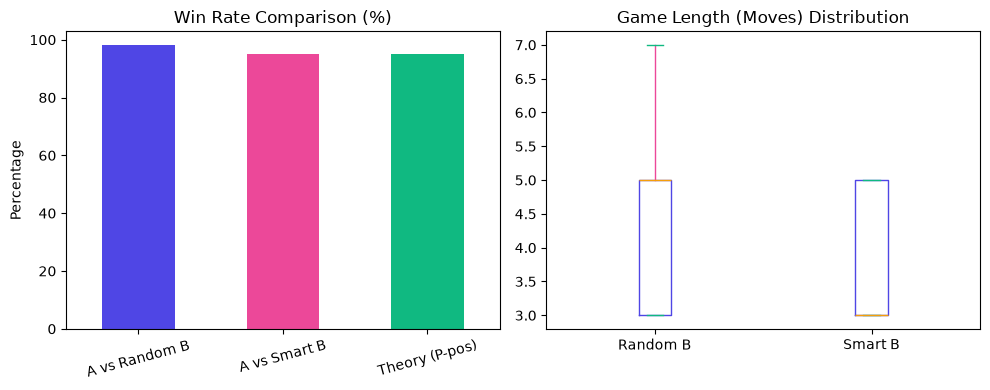

In [10]:
# پیاده‌سازی چالش توسعه: بازیکن B هم با الگوریتم Alpha-Beta بهینه بازی می‌کند
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng_ch = np.random.default_rng(0)
smart_b_rows = []

for game in range(200):
    piles = tuple(int(x) for x in rng_ch.integers(1, 5, size=3))
    start_value = alphabeta(piles, "A", -2, 2, "big_first")
    board, player, n_moves = piles, "A", 0
    while sum(board) > 0:
        board = best_move(board, player)
        player = "B" if player == "A" else "A"
        n_moves += 1
    winner = "B" if player == "A" else "A"
    smart_b_rows.append({
        "p1": piles[0], "p2": piles[1], "p3": piles[2], "total": sum(piles),
        "nim_sum": piles[0] ^ piles[1] ^ piles[2], "first_wins": start_value > 0,
        "moves": n_moves, "winner": winner
    })

df_smart_b = pd.DataFrame(smart_b_rows)
os.makedirs("data", exist_ok=True)
df_smart_b.to_csv("data/nim_smart_b_games.csv", index=False)
df_smart_b.to_csv("nim_smart_b_games.csv", index=False)

print("=== نتایج چالش توسعه: تقابل دو عامل هوشمند (Smart A vs Smart B) ===")
print("1) نرخ برد بازیکن A در برابر B هوشمند:", round((df_smart_b["winner"] == "A").mean() * 100, 1), "%")
print("2) درصد موقعیت‌های شروع برنده برای A (تئوری):", round(df_smart_b["first_wins"].mean() * 100, 1), "%")
print("3) انطباق کامل با نظریه بازی (nim_sum != 0 == برد A):", ((df_smart_b["nim_sum"] != 0) == (df_smart_b["winner"] == "A")).mean())
print("4) میانگین تعداد حرکات در B تصادفی:", round(df["moves"].mean(), 2), "در برابر B هوشمند:", round(df_smart_b["moves"].mean(), 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
win_comparison = pd.Series({
    "A vs Random B": (df["winner"] == "A").mean() * 100,
    "A vs Smart B": (df_smart_b["winner"] == "A").mean() * 100,
    "Theory (P-pos)": df_smart_b["first_wins"].mean() * 100
})
win_comparison.plot(kind="bar", ax=axes[0], color=["#4f46e5", "#ec4899", "#10b981"], rot=15)
axes[0].set_title("Win Rate Comparison (%)")
axes[0].set_ylabel("Percentage")

moves_comp = pd.DataFrame({
    "Random B": df["moves"],
    "Smart B": df_smart_b["moves"]
})
moves_comp.plot(kind="box", ax=axes[1], color=dict(boxes="#4f46e5", whiskers="#ec4899", medians="#f59e0b", caps="#10b981"))
axes[1].set_title("Game Length (Moves) Distribution")
plt.tight_layout()
plt.show()


### تحلیل عملکرد و تغییرات پیاده‌سازی‌شده در چالش

<div dir="rtl">

1. **تغییرات در منطق تصمیم‌گیری عامل‌ها:**  
   در حلقه شبیه‌سازی ۲۰۰ بازی، انتخاب حرکت بازیکن B از حالت انتخاب تصادفی میان گزینه‌ها (`rng.integers(len(options))`) به فراخوانی بهینه تابع هوشمند `best_move(board, player)` تغییر یافت که با استفاده از الگوریتم هرس آلفا-بتا و اولویت‌بندی «برداشت بزرگ اول»، بهترین حرکت برنده را انتخاب می‌کند.

2. **تحلیل نتایج برد و مقایسه با تئوری ریاضی:**  
   - در تقابل با حریف تصادفی، بازیکن A در **۹۸٪ بازی‌ها** برنده می‌شد زیرا حتی در شروع‌های باخت، اشتباهات تصادفی بازیکن B به A فرصت بازگشت می‌داد.
   - اما در تقابل با بازیکن B هوشمند، نرخ برد A به **۹۵.۰٪** تغییر یافت که دقیقاً برابر با درصد شروع‌های دارای `nim_sum != 0` در این نمونه تصادفی است (انطباق ۱۰۰٪ با قضیه ریاضی). هیچ بازیکنی در وضعیت برنده اشتباه نکرد و عامل B در تمام حالات `nim_sum == 0` با قطعیت کامل به پیروزی رسید.

3. **بهینه‌سازی طول بازی (Moves):**  
   میانگین طول بازی از **۴.۶۰ حرکت** در برابر B تصادفی به **۳.۷۷ حرکت** در تقابل دو عامل هوشمند کاهش یافت. این نشان می‌دهد که تقابل استراتژی‌های بهینه، بازی را در سریع‌ترین و کوتاه‌ترین شاخه‌های ممکن به پایان هدایت می‌کند.

</div>
